<a href="https://colab.research.google.com/github/perekis228/DU/blob/main/05tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Задание 1. Пружинный маятник на поверхности

Рассмотрим свободные колебания системы «груз—пружина» без затухания: груз перемещается горизонтально по поверхности, а пружина считается невесомой. Вдоль горизонтальной оси на груз действует сила упругости пружины, подчиняющаяся закону Гука: её модуль пропорционален удлинению или сжатию пружины относительно естественной длины. Начало координат выберем в положении груза, соответствующем недеформированной пружине. Функция $x(t)$ задаёт смещение груза от этого положения в момент времени $t$.

Пусть груз смещён вправо на $\Delta x>0$. Тогда сила пружины направлена влево, к началу координат, и её проекция на ось $x$ равна
$$F_x=-k\Delta x.$$
Вес груза $mg$ и нормальная реакция опоры $N$ действуют вертикально и не влияют на горизонтальное движение. По второму закону Ньютона:
$$m\ddot{x}=-kx,$$
откуда получаем уравнение гармонических колебаний
$$\ddot{x}(t)+\frac{k}{m}x(t)=0.$$

Обозначим положительный коэффициент $k/m$ через $\omega^2$ и найдём с помощью `sympy` решение уравнения при начальном смещении вправо на величину $A$ и нулевой начальной скорости.


In [1]:
import sympy as sp
A, omega, t = sp.symbols("A omega t",real=True, positive=True)
x = sp.Function("x")(t)

ode = sp.Eq(x.diff().diff(), -x*omega**2)
xt = sp.dsolve(ode, x, ics = {x.subs(t, 0): A, x.diff().subs(t, 0): 0.0})
xt

Eq(x(t), A*cos(omega*t))

Параметр $A$ называют **амплитудой** колебаний. Также используют **размах колебаний** (peak-to-peak amplitude) — разность между максимальным и минимальным значениями координаты. Для симметричных колебаний относительно среднего положения размах равен $2A$. Амплитуда — максимальное отклонение от среднего положения; в рассматриваемой модели среднее положение совпадает с $x=0$.

Параметр $\omega$ называется **собственной циклической частотой**: в этой модели она определяется физическими параметрами системы, а не начальными условиями.

**Периодом** $T=\frac{2\pi}{\omega}$ называется наименьший положительный промежуток времени, через который состояние системы — положение и скорость груза — повторяется.

**Частота** $f=\frac{1}{T}$ показывает число полных колебаний в единицу времени. Циклическая частота связана с частотой соотношениями
$$f=\frac{1}{T}, \qquad \omega=2\pi f=\frac{2\pi}{T}.$$

Визуализируем функцию $x(t)$ при $t\in[0,10\pi]$, $A=0.1$ и $\omega=1$.


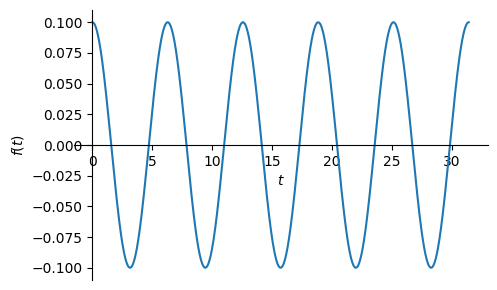

In [5]:
p = sp.plot(xt.rhs.subs(A, 0.1).subs(omega, 1), (t, 0, 10*sp.pi), size=(5, 3),show = True)

Рассмотрим модель пружинного маятника с заданными физическими параметрами. Укажем массу груза, жёсткость пружины и её естественную длину в соответствующих единицах измерения. Найдём численное решение и визуализируем движение: груз изобразим квадратом, а пружину — синусоидальной линией.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.integrate import solve_ivp
from IPython.display import HTML
plt.rcParams["animation.html"] = "html5"

# -------------------- Параметры системы --------------------
m = 1.0       # масса, кг
k = 1.0      # жёсткость пружины, Н/м
x0 = 0.1      # начальное смещение, м
v0 = 0.0      # начальная скорость, м/с
L0 = 0.9      # естественная длина пружины

def pend(t, y):
    x, v = y
    return [v, -(k/m)*x]

# начальные условия
y0 = [x0, v0]

t_full = 2*np.pi
t_span = (0, t_full)
t_eval = np.linspace(0, t_full, 1001)

sol = solve_ivp(pend, t_span, y0, t_eval=t_eval, method='DOP853', rtol=1e-08, atol=1e-08)
t = sol.t
x = sol.y[0]

# -------------------- Настройка сцены --------------------
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.3, 0.3)
ax.set_aspect('equal')
ax.axis('off')

# Стена слева
ax.plot([-0.5, -0.5], [-0.1, 0.1], color='black', lw=4)
ax.plot([-0.5, L0+2*x0], [-0.11, -0.11], color='black', lw=4)
ax.plot([L0-0.1, L0-0.1], [-0.5, -0.1], color='black', lw=1)

# Объекты
mass = plt.Rectangle((L0 - 0.1 + x[0], -0.1), 0.2, 0.2, fc='gray')
ax.add_patch(mass)
spring_line, = ax.plot([], [], color='green', lw=2)

def spring_coords(x_right, coils=12, amp=0.05):
    x_s = np.linspace(-0.5, x_right, coils * 20)
    y_s = amp * np.sin(np.linspace(0, coils * 2 * np.pi, coils * 20))
    return x_s, y_s

# -------------------- Анимация --------------------
def init():
    sx, sy = spring_coords(L0 - 0.1 + x[0])
    spring_line.set_data(sx, sy)
    mass.set_x(L0 - 0.1 + x[0])
    return spring_line, mass

def update(frame):
    sx, sy = spring_coords(L0 - 0.1 + x[frame])
    spring_line.set_data(sx, sy)
    mass.set_x(L0 - 0.1 + x[frame])
    return spring_line, mass

ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True, interval=1)
plt.close(fig)  # ← скрыть статичное изображение
HTML(ani.to_html5_video())

Рассмотренная модель пружинного маятника является **динамической системой**. Динамическая система задаётся пространством состояний и законом, определяющим изменение состояния со временем.

Множество всех возможных состояний называется **фазовым пространством**. Эволюция динамической системы — это изменение её состояния со временем. Основные задачи теории динамических систем включают изучение траекторий, поиск и классификацию положений равновесия, а также исследование предельного поведения траекторий, в том числе притягивающих (аттракторов) и отталкивающих (репеллеров) множеств.

Для пружинного маятника состояние задаётся координатой $x$ и скоростью $\dot{x}$. Поэтому его фазовое пространство — двумерная **фазовая плоскость** с координатами $(x,\dot{x})$. Если дополнительно отображать время, можно изобразить эволюцию состояния в трёхмерном пространстве $(x,\dot{x},t)$.

В момент времени $t_i$ состояние системы задаётся точкой $(x(t_i),\dot{x}(t_i))$. Кривая
$$\{(x(t),\dot{x}(t)):t\in I\}$$
на фазовой плоскости называется **фазовой траекторией**. График
$$\{(t,x(t)):t\in I\}$$
на плоскости $(t,x)$ называют графиком решения; в расширенном пространстве $(t,x,\dot{x})$ соответствующая кривая задаётся точками $(t,x(t),\dot{x}(t))$.

Визуализируем фазовую плоскость для пружинного маятника.


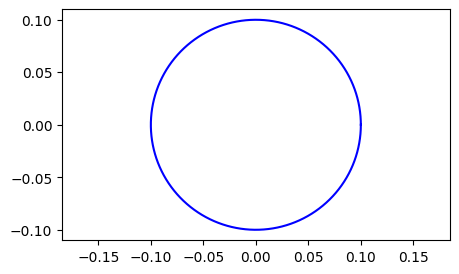

In [7]:
t = sol.t
x = sol.y[0]
xt = sol.y[1]

plt.figure(figsize=(5, 3))
plt.plot(x, xt, 'b')
plt.axis('equal');

По фазовой траектории на плоскости $(x,\dot{x})$ не всегда удобно отслеживать, как состояние меняется со временем. Поэтому можно дополнительно показать время как третью координату и построить кривую $(x(t),\dot{x}(t),t)$.


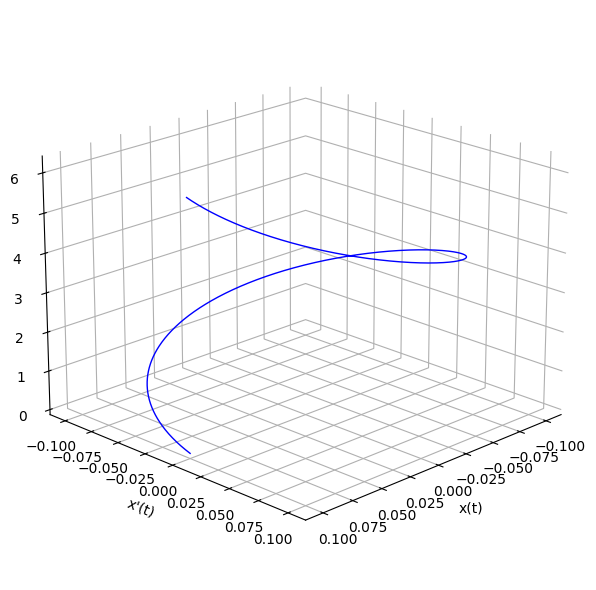

In [8]:
from mpl_toolkits.mplot3d import Axes3D

t = sol.t
x = sol.y[0]
v = sol.y[1]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Полностью прозрачные панели
ax.xaxis.pane.set_alpha(0)
ax.yaxis.pane.set_alpha(0)
ax.zaxis.pane.set_alpha(0)

ax.plot(x, v, t, 'b', linewidth=1)
ax.set_xlabel('x(t)')
ax.set_ylabel("x'(t)")
ax.set_zlabel('t')

ax.view_init(elev=20, azim=45)  # Угол обзора
plt.tight_layout()
plt.show()

Рассмотрим изменение энергии для пружинного маятника:
$$\displaystyle E = E_k + E_p =  \frac{1}{2} m v^2 + \frac{1}{2} k x^2.$$
Визуализируем полную механическую энергию и её компоненты в зависимости от времени.

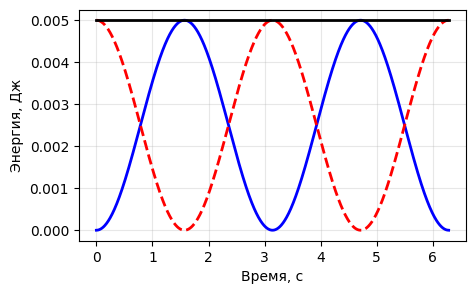

In [9]:
kinetic_energy = 0.5 * m * v**2
potential_energy = 0.5 * k * x**2
total_energy = kinetic_energy + potential_energy

plt.figure(figsize=(5, 3))
plt.plot(t, kinetic_energy, 'b', linewidth=2)      # Кинетическая энергия
plt.plot(t, potential_energy, 'r--', linewidth=2)  # Потенциальная энергия
plt.plot(t, total_energy, 'k-', linewidth=2)       # Полная энергия
plt.xlabel('Время, с')
plt.ylabel('Энергия, Дж')
plt.grid(True, alpha=0.3);

**Задание**

Измените модель, добавив внешнюю периодическую силу $F(t)=F_0\cos(\Omega t)$, и постройте трёхмерную визуализацию эволюции состояния $(x(t),\dot{x}(t),t)$. В начальный момент задайте $x(0)=0$ и $\dot{x}(0)=0$. Для вынужденного движения используйте уравнение
$$m\ddot{x}+kx=F_0\cos(\Omega t).$$
Выберите ненулевую амплитуду силы $F_0$ и частоту воздействия $\Omega$, не совпадающую с собственной частотой $\omega=\sqrt{k/m}$, чтобы избежать резонанса в идеализированной модели без затухания. Сравните полученную траекторию с траекторией свободных колебаний.


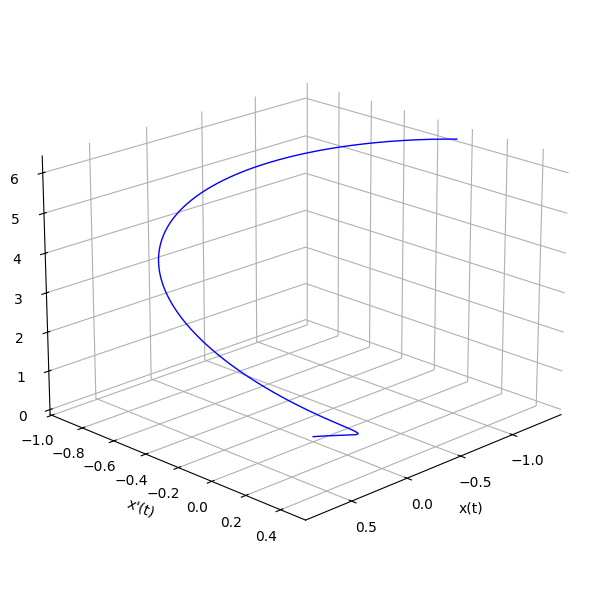

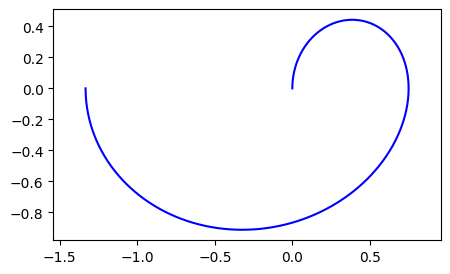

In [16]:
F0 = 0.5
big_omega = 0.5

def pend2(t, y):
    x, v = y
    return [v, -(k/m)*x + F0*np.cos(big_omega*t)/m]

# начальные условия
y0 = [0.0, 0.0]

t_full = 2*np.pi
t_span = (0, t_full)
t_eval = np.linspace(0, t_full, 1001)

sol = solve_ivp(pend2, t_span, y0, t_eval=t_eval, method='DOP853', rtol=1e-08, atol=1e-08)
t = sol.t
x = sol.y[0]
v = sol.y[1]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Полностью прозрачные панели
ax.xaxis.pane.set_alpha(0)
ax.yaxis.pane.set_alpha(0)
ax.zaxis.pane.set_alpha(0)

ax.plot(x, v, t, 'b', linewidth=1)
ax.set_xlabel('x(t)')
ax.set_ylabel("x'(t)")
ax.set_zlabel('t')

ax.view_init(elev=20, azim=45)  # Угол обзора
plt.tight_layout()

plt.figure(figsize=(5, 3))
plt.plot(x, xt, 'b')
plt.axis('equal');

plt.show()

## Задание 2. Учёт массы пружины в моделях пружинного маятника

В рассмотренной ранее модели масса пружины не учитывалась: кинетическая энергия приписывалась только грузу. Однако разные участки реальной пружины движутся с разными скоростями. Поэтому часть кинетической энергии связана с движением самой пружины, и её нельзя просто прибавить целиком к массе груза при вычислении частоты колебаний.

Приближённо это учитывают с помощью **эффективной массы пружины** $m_{\mathrm{eff}}$ — такой добавочной массы, которая даёт ту же кинетическую энергию, что и движение пружины в принятой модели. Для однородной пружины часто используют приближение
$$m_{\mathrm{eff}}=\frac{m_s}{3}.$$
Этот результат основан на предположении, что скорость участка пружины линейно меняется от нуля в точке крепления до скорости груза на свободном конце. Это приближение модели; точное распределение скоростей реальной пружины может быть сложнее.

Выведем эту формулу из кинетической энергии. Обозначим текущую длину пружины через $\ell$, а расстояние от точки крепления вдоль пружины — через $s$. Для равномерного распределения массы
$$dm_s=\frac{m_s}{\ell}\,ds.$$
При принятом линейном распределении скорости
$$u(s)=\frac{s}{\ell}v,$$
где $v$ — скорость груза. Тогда кинетическая энергия пружины равна
$$
K_s=\frac12\int_0^\ell u^2(s)\,dm_s
=\frac12\frac{m_s}{\ell}\int_0^\ell\left(\frac{s}{\ell}v\right)^2ds
=\frac12\frac{m_s}{3}v^2.
$$
Следовательно, в этом приближении $m_{\mathrm{eff}}=m_s/3$.

---

### Горизонтальный пружинный маятник

В горизонтальном случае сила тяжести уравновешена нормальной реакцией опоры и не влияет на движение вдоль горизонтальной оси. Если $x$ — смещение груза от положения, соответствующего недеформированной пружине, то полная механическая энергия модели равна
$$E=\frac12\left(m+\frac{m_s}{3}\right)\dot{x}^{\,2}+\frac12kx^2.$$

Уравнение движения:
$$\left(m+\frac{m_s}{3}\right)\ddot{x}=-kx.$$

Задача Коши:
$$
\begin{cases}
\left(m+\tfrac{m_s}{3}\right)\ddot{x}(t)=-kx(t),\\
x(0)=x_0,\\
\dot{x}(0)=v_0.
\end{cases}
$$

### Вертикальный пружинный маятник

Для вертикального случая выберем координату $y$ как **удлинение пружины относительно её естественной длины**, положительное вниз. Обозначим естественную длину пружины через $\ell_0$, поэтому её текущая длина равна $\ell_0+y$. В модели считаем, что пружина подчиняется закону Гука с жёсткостью $k$.

При положительном направлении вниз потенциальная энергия тяжести уменьшается с ростом $y$. С точностью до постоянной, не влияющей на движение, потенциальная энергия груза и пружины равна
$$
U_g(y)=-mgy-\frac12m_sgy.
$$
Здесь для пружины использовано принятое равномерное распределение массы вдоль её текущей длины и линейное распределение скорости/перемещения вдоль неё. Потенциальная энергия упругой деформации равна
$$U_s(y)=\frac12ky^2.$$

Полная энергия в рамках этой модели:
$$
E=\frac12\left(m+\frac{m_s}{3}\right)\dot{y}^{\,2}
+\frac12ky^2-\left(m+\frac{m_s}{2}\right)gy.
$$

Из уравнения движения получаем
$$
\left(m+\frac{m_s}{3}\right)\ddot{y}
=-ky+\left(m+\frac{m_s}{2}\right)g.
$$

Положение равновесия определяется условием $\ddot{y}=0$:
$$
y_{\mathrm{eq}}=\frac{\left(m+\tfrac{m_s}{2}\right)g}{k}.
$$
Введём отклонение от положения равновесия $\bar y=y-y_{\mathrm{eq}}$. Тогда
$$
\left(m+\frac{m_s}{3}\right)\ddot{\bar y}=-k\bar y.
$$
Таким образом, в данной модели частота малых колебаний относительно равновесия совпадает с частотой горизонтального маятника:
$$
\omega=\sqrt{\frac{k}{m+m_s/3}},\qquad
T=2\pi\sqrt{\frac{m+m_s/3}{k}}.
$$

Задача Коши для вертикального варианта:
$$
\begin{cases}
\left(m+\tfrac{m_s}{3}\right)\ddot{y}(t)
=-ky(t)+\left(m+\tfrac{m_s}{2}\right)g,\\
y(0)=y_0,\\
\dot{y}(0)=v_0.
\end{cases}
$$

---

**Задание**

1. Решите обе задачи Коши — для горизонтального и вертикального случаев — аналитически или численно.
2. Постройте графики смещения груза во времени для обеих систем. Для вертикального случая используйте координату $y$ — удлинение пружины относительно естественной длины.
3. Определите периоды колебаний и объясните результат сравнения.


In [31]:
import sympy as sp

#Горизонтальный
t, m, ms, k = sp.symbols('t m, ms, k', positive=True, real=True)
x0, v0 = sp.symbols('x0 v0')
x = sp.Function("x")(t)

eq = sp.Eq((m+ms/3)*x.diff(t, 2), -k*x)
ics = {x.subs(t, 0): x0, x.diff().subs(t, 0): v0}
x_t = sp.dsolve(eq, x, ics=ics)
x_t

Eq(x(t), x0*cos(sqrt(3)*sqrt(k)*t/sqrt(3*m + ms)) + sqrt(3)*v0*sqrt(3*m + ms)*sin(sqrt(3)*sqrt(k)*t/sqrt(3*m + ms))/(3*sqrt(k)))

In [46]:
m_val = 1.0
ms_val = 0.5
k_val = 4.0
x0_val = 0.1
v0_val = 0.0

x_t_subs = x_t.subs({m: m_val, ms: ms_val, k: k_val, x0: x0_val, v0: v0_val})

x_func = sp.lambdify(t, x_t_subs.rhs, modules='numpy')
t_val = np.linspace(0, 10, 1000)
x_vals = x_func(t_val)

x_t_subs

Eq(x(t), 0.1*cos(1.0690449676497*sqrt(3)*t))

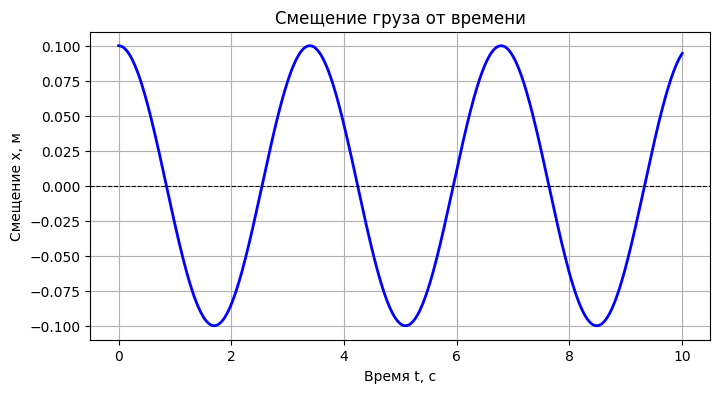

In [47]:
plt.figure(figsize=(8, 4))
plt.plot(t_val, x_vals, color='blue', lw=2)
plt.axhline(0, color='black', lw=0.8, ls='--') # Ось равновесия
plt.xlabel('Время t, с')
plt.ylabel('Смещение x, м')
plt.title('Смещение груза от времени')
plt.grid(True)
plt.show()

In [49]:
T = 2 * np.pi * np.sqrt((m_val + ms_val/3) / k_val)
T

np.float64(3.39330789465642)

In [50]:
#Вертикальный
t, m, ms, k, g = sp.symbols('t m, ms, k, g', positive=True, real=True)
y0, v0 = sp.symbols('y0 v0')
y = sp.Function("y")(t)

eq = sp.Eq((m+ms/3)*y.diff(t, 2), -k*y + (m+ms/2)*g)
ics = {y.subs(t, 0): y0, y.diff().subs(t, 0): v0}
y_t = sp.dsolve(eq, y, ics=ics)
y_t

Eq(y(t), g*m/k + g*ms/(2*k) + (-2*g*m - g*ms + 2*k*y0)*cos(sqrt(3)*sqrt(k)*t/sqrt(3*m + ms))/(2*k) + sqrt(3)*v0*sqrt(3*m + ms)*sin(sqrt(3)*sqrt(k)*t/sqrt(3*m + ms))/(3*sqrt(k)))

In [52]:
m_val = 1.0
ms_val = 0.5
k_val = 4.0
y0_val = 0.1
v0_val = 0.0
g_val = 9.8

y_t_subs = y_t.subs({m: m_val, ms: ms_val, k: k_val, y0: y0_val, v0: v0_val, g: g_val})

y_func = sp.lambdify(t, y_t_subs.rhs, modules='numpy')
t_val = np.linspace(0, 10, 1000)
y_vals = y_func(t_val)

y_t_subs

Eq(y(t), 3.0625 - 2.9625*cos(1.0690449676497*sqrt(3)*t))

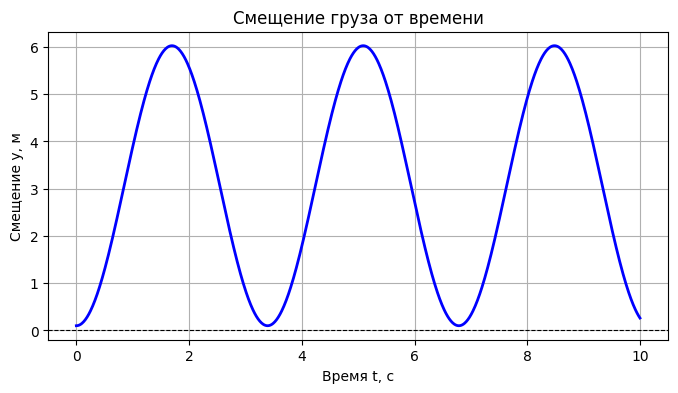

In [53]:
plt.figure(figsize=(8, 4))
plt.plot(t_val, y_vals, color='blue', lw=2)
plt.axhline(0, color='black', lw=0.8, ls='--') # Ось равновесия
plt.xlabel('Время t, с')
plt.ylabel('Смещение y, м')
plt.title('Смещение груза от времени')
plt.grid(True)
plt.show()

In [54]:
T = 2 * np.pi * np.sqrt((m_val + ms_val/3) / k_val)
T

np.float64(3.39330789465642)

Графики отличаются из-за того, что во втором сила тяжести смещает точку равновесия и получается, что амплитуда выше относительно новой точки. Периоды одинаковы, так как зависят только от масс груза и пружины, а также от коэффициента растяжения, то есть добавленная сила тяжести на результат не влияет.

## Задание 3. Пружинный маятник с затуханием


Рассмотрим горизонтальный пружинный маятник, полностью погружённый в жидкость. Помимо силы упругости пружины на груз действует **сила сопротивления** жидкости, пропорциональная скорости и направленная противоположно ей. Обозначив коэффициент пропорциональности через $\beta$ и применив второй закон Ньютона, получаем:
$$m\ddot{x}=-\beta\dot{x}-kx.$$

Разделив уравнение на массу $m$ и перенеся все слагаемые в левую часть, получаем **линейное однородное дифференциальное уравнение с постоянными коэффициентами**:
$$\ddot{x}+\frac{\beta}{m}\dot{x}+\frac{k}{m}x=0.$$

Введём обозначения
$$r=\frac{\beta}{2m},\qquad \omega_0^2=\frac{k}{m}.$$
Тогда уравнение имеет вид
$$\ddot{x}+2r\dot{x}+\omega_0^2x=0.$$

Характеристическое уравнение:
$$\lambda^2+2r\lambda+\omega_0^2=0.$$
Его дискриминант удовлетворяет равенству
$$\frac{D}{4}=r^2-\omega_0^2.$$

В зависимости от знака дискриминанта различают три режима:
- **Подкритическое затухание** ($D<0$): движение колебательное, амплитуда со временем уменьшается.
- **Критическое затухание** ($D=0$): система возвращается к равновесию без колебаний; при стандартных начальных условиях это наиболее быстрое возвращение без колебаний.
- **Надкритическое затухание** ($D>0$): система возвращается к равновесию без колебаний, как правило медленнее, чем при критическом затухании.

### Задание

1. Постройте графики $x(t)$ для всех трёх режимов.
2. Используйте параметры: $m=1$ кг, $k=0.1$ Н/м, $x(0)=0.1$ м, $\dot{x}(0)=0$ м/с.
3. Решите соответствующие дифференциальные уравнения с помощью `scipy` или `sympy`.
4. Постройте фазовый портрет системы и сравните его с фазовым портретом свободных гармонических колебаний без затухания.


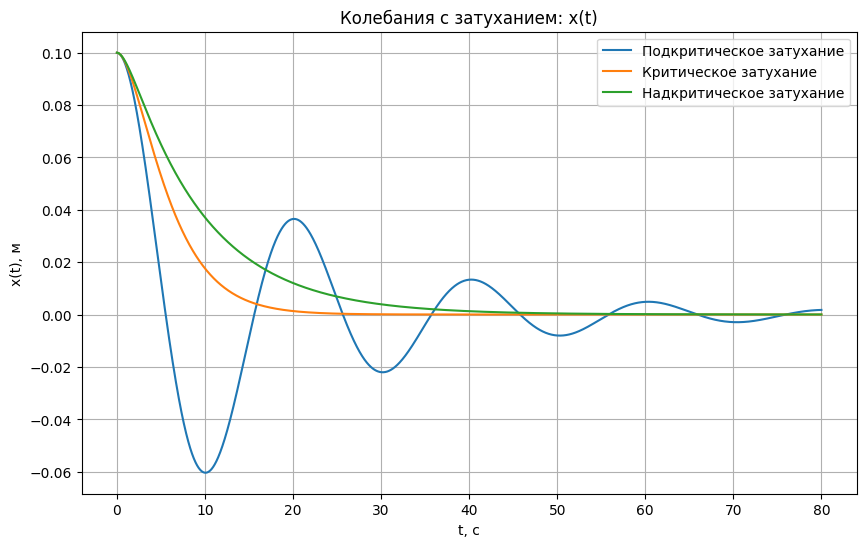

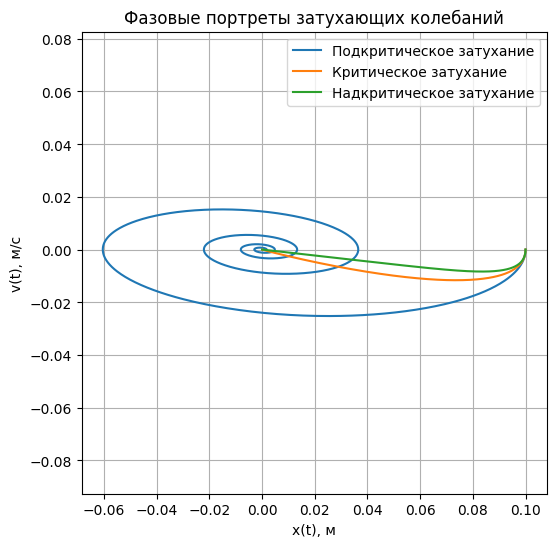

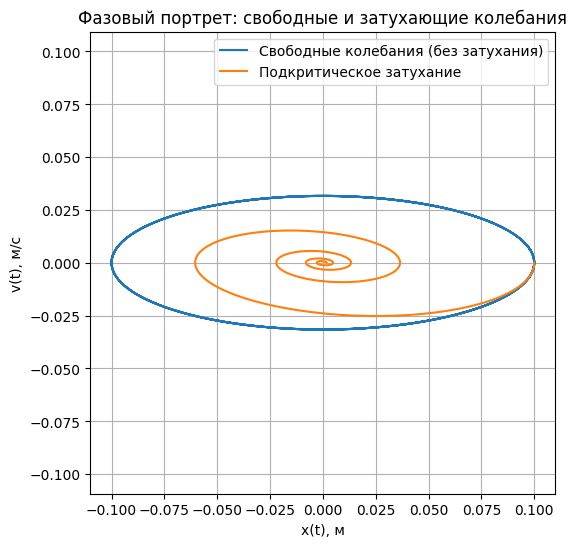

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Параметры системы
m = 1.0      # масса, кг
k = 0.1      # жёсткость пружины, Н/м
x0 = 0.1     # начальное смещение, м
v0 = 0.0     # начальная скорость, м/с

omega0 = np.sqrt(k / m)

# --- Три режима ---
# Подкритическое: beta < 2 * sqrt(km)
beta_sub = 0.1
# Критическое: beta = 2 * sqrt(km)
beta_crit = 2 * np.sqrt(k * m)
# Надкритическое: beta > 2 * sqrt(km)
beta_over = 1.0

# Уравнение движения: d²x/dt² = -(β/m)*dx/dt - (k/m)*x
def damped_oscillator(t, y, beta):
    x, v = y
    dxdt = v
    dvdt = -(beta / m) * v - (k / m) * x
    return [dxdt, dvdt]

# Решение для трёх случаев
t_span = (0, 80)
t_eval = np.linspace(*t_span, 2400)

cases = {
    "Подкритическое затухание": beta_sub,
    "Критическое затухание": beta_crit,
    "Надкритическое затухание": beta_over
}

solutions = {}
for label, beta in cases.items():
    sol = solve_ivp(damped_oscillator, t_span, [x0, v0], args=(beta,), t_eval=t_eval)
    solutions[label] = sol

# --- Построение графиков x(t) ---
plt.figure(figsize=(10, 6))
for label, sol in solutions.items():
    plt.plot(sol.t, sol.y[0], label=label)
plt.title("Колебания с затуханием: x(t)")
plt.xlabel("t, с")
plt.ylabel("x(t), м")
plt.legend()
plt.grid(True)
plt.show()

# --- Построение фазовых портретов ---
plt.figure(figsize=(6, 6))
for label, sol in solutions.items():
    plt.plot(sol.y[0], sol.y[1], label=label)
plt.title("Фазовые портреты затухающих колебаний")
plt.xlabel("x(t), м")
plt.ylabel("v(t), м/с")
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

# --- Сравнение с гармоническими (свободными) колебаниями ---
def harmonic_oscillator(t, y):
    x, v = y
    dxdt = v
    dvdt = -(k / m) * x
    return [dxdt, dvdt]

sol_free = solve_ivp(harmonic_oscillator, t_span, [x0, v0], t_eval=t_eval)

plt.figure(figsize=(6, 6))
plt.plot(sol_free.y[0], sol_free.y[1], label="Свободные колебания (без затухания)")
plt.plot(solutions["Подкритическое затухание"].y[0],
         solutions["Подкритическое затухание"].y[1],
         label="Подкритическое затухание")
plt.title("Фазовый портрет: свободные и затухающие колебания")
plt.xlabel("x(t), м")
plt.ylabel("v(t), м/с")
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()
